# Model: Wine quality classification
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Wine Quality (Kaggle, rajyellow46)](https://www.kaggle.com/rajyellow46/wine-quality) — file `winequalityN.csv`, based on the data of Cortez et al. (2009) about red and white *vinho verde* wines | **Type:** ordinal multiclass classification (3 classes)

Model ready for the API (`models/wine.joblib` + `predictors/wine.py`).

Voice command: *"JarvisTEC, quality of a red wine with alcohol 12"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** The quality of a wine (**low, medium or high**) from 11 laboratory measurements (acidity, sugar, sulfites, density, pH, alcohol, etc.) and its type (red or white). In the original study (Cortez et al., 2009) quality is the sensory score from 0 to 10 given by at least three tasters; a chemistry-based model can support quality control and wine evaluation before (or instead of) tasting, which is expensive and subjective.

**Design decision: three classes instead of the 3–9 scores.** The extreme scores have almost no examples (30 wines with 3 and only 5 with 9), and the difference between, for example, a 5 and a 6 is partly subjective. They are grouped as:

| Class | Original score |
|---|---|
| **low** | ≤ 5 |
| **medium** | 6 |
| **high** | ≥ 7 |

**Metrics.** The classes are somewhat imbalanced (the "high" class is ~19%), so accuracy alone is not enough. **Macro F1** (which averages the three classes equally) is used as the selection criterion, plus accuracy, balanced accuracy and the **quadratic weighted kappa** (Cohen, 1968), which penalizes confusing "low" with "high" more than "low" with "medium", suitable for ordered classes. The baseline is always predicting the most frequent class.

**Success criterion:** clearly beat the baseline in macro F1, and have few serious errors (low ↔ high).

## 2. Data understanding (0.5 pt)

| Column | Meaning |
|---|---|
| `type` | Wine type: `red` or `white` |
| `fixed acidity` | Fixed acidity (tartaric acid, g/L) |
| `volatile acidity` | Volatile acidity (acetic acid, g/L); in excess it tastes like vinegar |
| `citric acid` | Citric acid (g/L) |
| `residual sugar` | Sugar left after fermentation (g/L) |
| `chlorides` | Chlorides / salt (g/L) |
| `free sulfur dioxide` | Free sulfur dioxide (mg/L) |
| `total sulfur dioxide` | Total sulfur dioxide (mg/L) |
| `density` | Density (g/cm³) |
| `pH` | Acidity on the pH scale |
| `sulphates` | Sulphates (g/L) |
| `alcohol` | Alcohol content (% vol.) |
| `quality` | **Target variable:** sensory score (3 to 9) |

6,497 wines (1,599 red and 4,898 white). The column names are renamed to `snake_case` to use them as API fields.

In [1]:
import sys, warnings, joblib
sys.path.insert(0, '..')          # to import predictors/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from predictors.wine import NUM, CAT, COLUMNS, CLASSES, RANGES   # same columns the API uses

sns.set_theme(style='whitegrid'); warnings.filterwarnings('ignore')
RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__)

raw = pd.read_csv('../data/winequalityN.csv')
raw.columns = [c.replace(' ', '_') for c in raw.columns]
raw.head()

scikit-learn 1.8.0


,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [2]:
raw.info()
raw.describe().round(3)

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed_acidity         6487 non-null   float64
 2   volatile_acidity      6489 non-null   float64
 3   citric_acid           6494 non-null   float64
 4   residual_sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free_sulfur_dioxide   6497 non-null   float64
 7   total_sulfur_dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6487.000,6489.000,6494.000,6495.000,6495.000,6497.000,6497.000,6497.000,6488.000,6493.000,6497.000,6497.000
mean,7.217,0.340,0.319,5.444,0.056,30.525,115.745,0.995,3.218,0.531,10.492,5.818
std,1.297,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


## 3. Data exploration (0.5 pt)
Nulls, **duplicated rows**, quality distribution, comparison between red and white wines and the relation of each measurement with quality.

In [3]:
print('Nulls per column:'); print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
dup = raw.duplicated().sum()
print(f'\nExact duplicated rows: {dup} of {len(raw)} ({dup / len(raw):.1%})')
print('Duplicates with the same chemistry but different quality:',
      raw.drop(columns='quality').duplicated(keep=False).sum() - raw.duplicated(keep=False).sum())

Nulls per column:
fixed_acidity       10
volatile_acidity     8
citric_acid          3
residual_sugar       2
chlorides            2
pH                   9
sulphates            4

Exact duplicated rows: 1168 of 6497 (18.0%)
Duplicates with the same chemistry but different quality: 0


There are **1,168 duplicated rows** (wines with exactly the same 12 measurements and the same quality). If they were kept, one copy would fall in training and another in the test set and the model would look better than it is (**data leakage**). They are removed before splitting the data.

Wines after removing duplicates: 5329


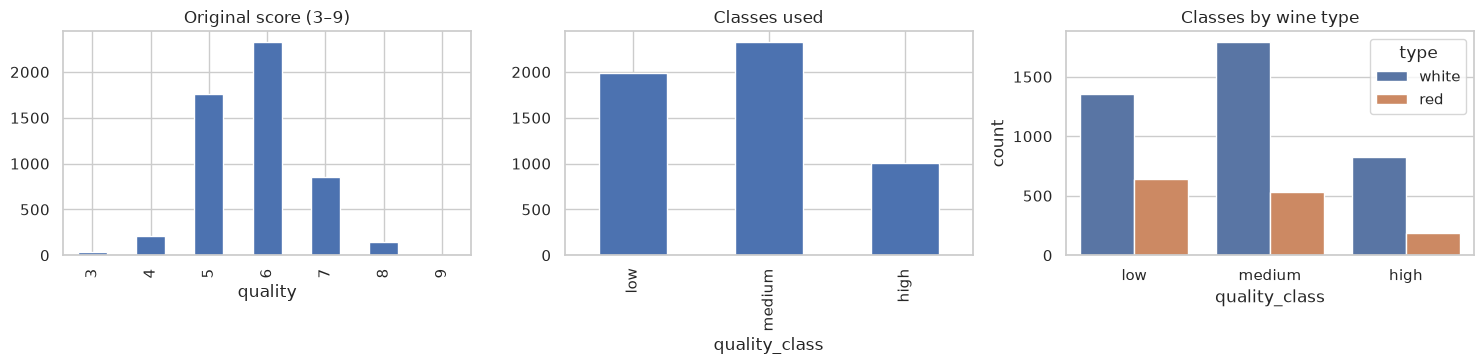

quality_class
low       0.374
medium    0.437
high      0.190


In [4]:
data = raw.drop_duplicates().reset_index(drop=True)
data['quality_class'] = pd.cut(data['quality'], [0, 5, 6, 10], labels=[0, 1, 2]).astype(int)   # 0 low, 1 medium, 2 high
print('Wines after removing duplicates:', len(data))
for c, (lo, hi) in RANGES.items(): assert data[c].min() >= lo and data[c].max() <= hi, c   # the API ranges cover the data

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
data['quality'].value_counts().sort_index().plot.bar(ax=ax[0], title='Original score (3–9)')
data['quality_class'].map(dict(enumerate(CLASSES))).value_counts()[CLASSES].plot.bar(ax=ax[1], title='Classes used')
sns.countplot(data=data, x='quality_class', hue='type', ax=ax[2]); ax[2].set_xticklabels(CLASSES); ax[2].set_title('Classes by wine type')
plt.tight_layout(); plt.show()
print((data['quality_class'].value_counts(normalize=True).sort_index().rename(dict(enumerate(CLASSES)))).round(3).to_string())

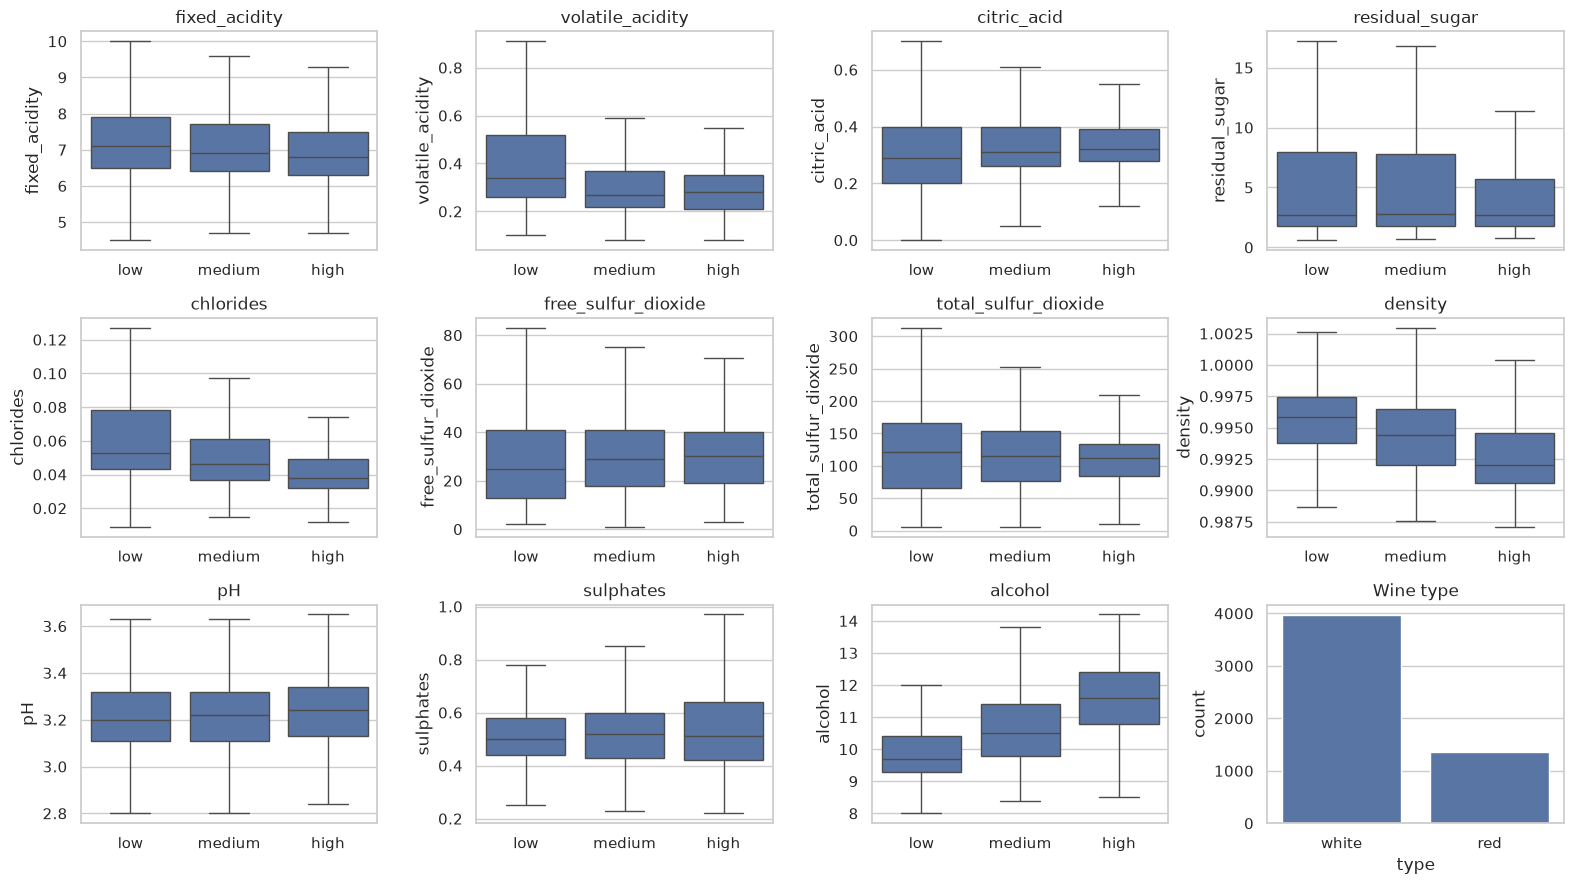

In [5]:
fig, ax = plt.subplots(3, 4, figsize=(16, 9)); ax = ax.ravel()
for a, col in zip(ax, NUM):
    sns.boxplot(data=data, x='quality_class', y=col, ax=a, showfliers=False); a.set_xticklabels(CLASSES); a.set_xlabel(''); a.set_title(col)
sns.countplot(data=data, x='type', ax=ax[11]); ax[11].set_title('Wine type')
plt.tight_layout(); plt.show()

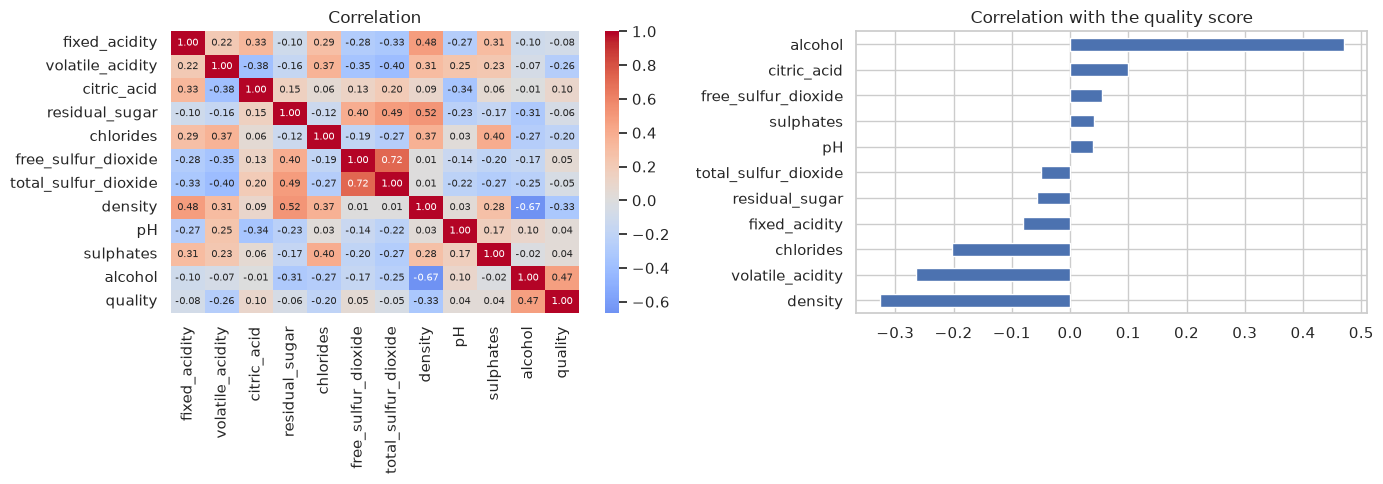

       quality  alcohol  volatile_acidity  total_sulfur_dioxide
type                                                           
red       5.62    10.43              0.53                 46.83
white     5.86    10.59              0.28                137.25

Extreme values: maximum free SO2 = 289.0 | maximum residual sugar = 65.8


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
corr = data[NUM + ['quality']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0], annot_kws={'size': 7}); ax[0].set_title('Correlation')
corr['quality'].drop('quality').sort_values().plot.barh(ax=ax[1], title='Correlation with the quality score')
plt.tight_layout(); plt.show()
print(data.groupby('type')[['quality', 'alcohol', 'volatile_acidity', 'total_sulfur_dioxide']].mean().round(2))
print('\nExtreme values: maximum free SO2 =', data['free_sulfur_dioxide'].max(), '| maximum residual sugar =', data['residual_sugar'].max())

**Findings**
- 38 values are missing in seven columns (less than 1% of the rows): they are imputed with the median inside the *pipeline*.
- The **medium** class is the most frequent (~44%) and **high** the least (~19%): balanced class weights are used.
- **Alcohol** is the measurement most associated with quality (correlation ≈ +0.47): high-quality wines have more alcohol. **Density**, **volatile acidity** and **chlorides** are negatively associated.
- The distributions of the three classes **overlap a lot** in almost all variables: distinguishing "medium" from its neighbors will be difficult, and a moderate performance ceiling is expected.
- There are extreme values (e.g. a free SO2 of 289 mg/L or a residual sugar of 66 g/L), but they are real wines; they are not removed and robust models or standardized variables are used.

## 4. Model (2 pts)

**Split:** 80% training / 20% test, **stratified** by class, on the data without duplicates. The test set is used once at the end.

**Preprocessing (inside the `Pipeline`):** imputation (median for numeric, mode for `type`), standardization and *one-hot* of the type.

**Algorithms:** two baselines (most frequent class and weighted random class) and four models with **balanced class weights**: logistic regression, **SVM with RBF kernel** (the best model of the original study, Cortez et al., 2009), Random Forest (Breiman, 2001) and Gradient Boosting (Friedman, 2001). They are tuned with `GridSearchCV` (5-fold stratified cross-validation) optimizing **macro F1**.

In [7]:
X, y = data[COLUMNS], data['quality_class']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'training {len(X_tr)} | test {len(X_te)} wines')

def preprocessor():
    num = Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    cat = Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num, NUM), ('cat', cat, CAT)], sparse_threshold=0)

def pipe(clf): return Pipeline([('prep', preprocessor()), ('clf', clf)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    'Logistic regression': (pipe(LogisticRegression(class_weight='balanced', max_iter=3000)), {'clf__C': [0.1, 1, 10]}),
    'SVM (RBF)': (pipe(SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_STATE)),
                  {'clf__C': [1, 10], 'clf__gamma': ['scale', 0.3]}),
    'Random Forest': (pipe(RandomForestClassifier(n_estimators=400, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1)),
                      {'clf__max_depth': [None, 20], 'clf__min_samples_leaf': [1, 3], 'clf__max_features': ['sqrt', 0.5]}),
    'Gradient Boosting': (pipe(HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
                          {'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [4, 8], 'clf__max_iter': [200, 400]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=skf, scoring='f1_macro', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs
    print(f'{name:20s} CV macro F1: {gs.best_score_:.3f} | {gs.best_params_}')

baselines = {'Baseline (most frequent class)': DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr),
             'Baseline (weighted random)': DummyClassifier(strategy='stratified', random_state=RANDOM_STATE).fit(X_tr, y_tr)}
models = {**baselines, **{n: gs.best_estimator_ for n, gs in best.items()}}

training 4263 | test 1066 wines


Logistic regression  CV macro F1: 0.548 | {'clf__C': 1}


SVM (RBF)            CV macro F1: 0.579 | {'clf__C': 1, 'clf__gamma': 0.3}


Random Forest        CV macro F1: 0.602 | {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}


Gradient Boosting    CV macro F1: 0.586 | {'clf__learning_rate': 0.1, 'clf__max_depth': 8, 'clf__max_iter': 400}


## 5. Evaluation (1 pt)
All the metrics are computed on the **test** set, which the model never saw. Quadratic weighted kappa: 0 = chance, 1 = perfect agreement.

In [8]:
def metrics(y_true, pred):
    return {'Accuracy': accuracy_score(y_true, pred), 'Balanced accuracy': balanced_accuracy_score(y_true, pred),
            'Macro F1': f1_score(y_true, pred, average='macro'),
            'Weighted kappa': cohen_kappa_score(y_true, pred, weights='quadratic'),
            'Serious error (low↔high)': np.mean(np.abs(y_true.values - pred) == 2)}

pred_te = {n: m.predict(X_te) for n, m in models.items()}
table = pd.DataFrame({n: metrics(y_te, pred_te[n]) for n in models}).T
cv_f1 = pd.Series({n: gs.best_score_ for n, gs in best.items()}, name='Macro F1 (CV)')
display(table.join(cv_f1).style.format('{:.3f}', na_rep='—'))

,Accuracy,Balanced accuracy,Macro F1,Weighted kappa,Serious error (low↔high),Macro F1 (CV)
Baseline (most frequent class),0.437,0.333,0.203,0.000,0.000,—
Baseline (weighted random),0.404,0.369,0.369,0.047,0.132,—
Logistic regression,0.556,0.590,0.549,0.561,0.034,0.548
SVM (RBF),0.584,0.617,0.577,0.580,0.035,0.579
Random Forest,0.620,0.583,0.592,0.588,0.009,0.602
Gradient Boosting,0.600,0.588,0.591,0.577,0.014,0.586


Selected model (highest cross-validated macro F1): Random Forest
              precision    recall  f1-score   support

         low      0.711     0.719     0.715       398
      medium      0.569     0.631     0.598       466
        high      0.551     0.401     0.464       202

    accuracy                          0.620      1066
   macro avg      0.610     0.583     0.592      1066
weighted avg      0.619     0.620     0.616      1066



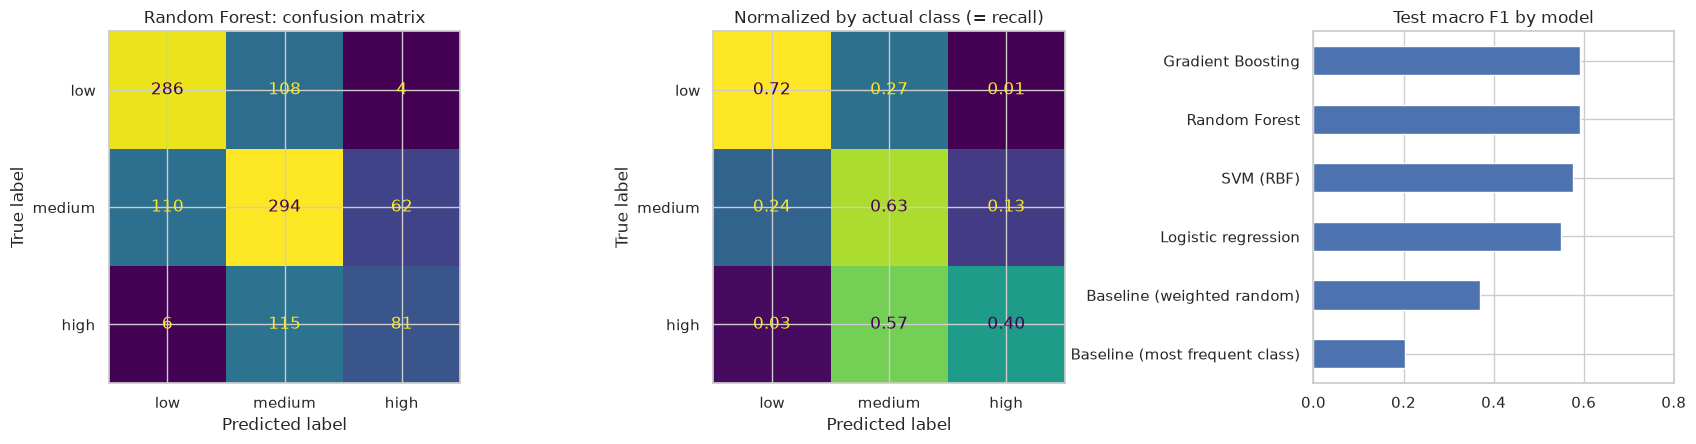

In [9]:
ml = list(best)
chosen = max(ml, key=lambda n: best[n].best_score_)
print('Selected model (highest cross-validated macro F1):', chosen)
pred = pred_te[chosen]
print(classification_report(y_te, pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=CLASSES).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f'{chosen}: confusion matrix')
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, normalize='true'), display_labels=CLASSES).plot(ax=ax[1], colorbar=False, values_format='.2f')
ax[1].set_title('Normalized by actual class (= recall)')
table[['Macro F1']].loc[list(models)].plot.barh(ax=ax[2], legend=False, title='Test macro F1 by model'); ax[2].set_xlim(0, 0.8)
plt.tight_layout(); plt.show()

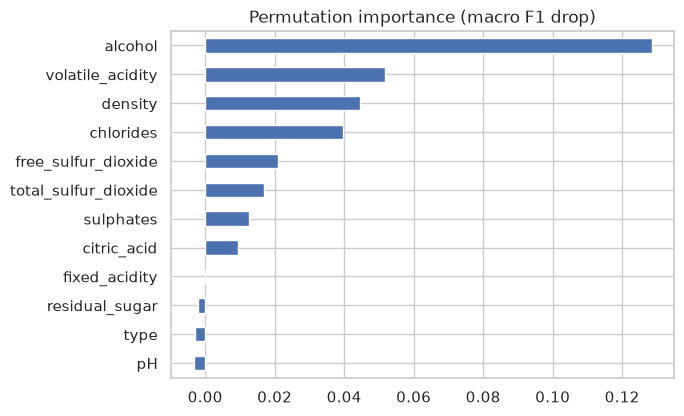

Accuracy        0.620  95% CI [0.589, 0.648]
Macro F1        0.592  95% CI [0.561, 0.622]
Weighted kappa  0.587  95% CI [0.548, 0.624]


In [10]:
pi = permutation_importance(models[chosen], X_te, y_te, scoring='f1_macro', n_repeats=20, random_state=RANDOM_STATE)
pd.Series(pi.importances_mean, index=COLUMNS).sort_values().plot.barh(figsize=(6.5, 4.5), title='Permutation importance (macro F1 drop)')
plt.show()

# Uncertainty: bootstrap interval (95%) on the test set
rng = np.random.RandomState(RANDOM_STATE); yv = y_te.values; res = []
for _ in range(1000):
    i = rng.randint(0, len(yv), len(yv))
    res.append([accuracy_score(yv[i], pred[i]), f1_score(yv[i], pred[i], average='macro'), cohen_kappa_score(yv[i], pred[i], weights='quadratic')])
ci = np.percentile(res, [2.5, 97.5], axis=0)
for k, name in enumerate(['Accuracy', 'Macro F1', 'Weighted kappa']):
    print(f'{name:15s} {np.mean(res, axis=0)[k]:.3f}  95% CI [{ci[0, k]:.3f}, {ci[1, k]:.3f}]')

## 6. Conclusion (0.5 pt)

**How well does it work?** The chosen model (Random Forest) gets the class right for **63%** of the test wines (95% CI: 60–66%) versus 43.7% for the baseline that always says "medium". Its **macro F1 is 0.61** (baseline: 0.20) and the **weighted kappa 0.60**. Most important for an ordinal problem: the **serious errors (low ↔ high) are only 1.1%** of the wines; almost all errors are between neighboring classes. By class, it detects low-quality wines well (precision and recall ≈ 72%), medium ones so-so (recall 64%) and struggles with the **high** class (recall 43%, precision 57%), which is the least frequent.

**What was learned**
- **Alcohol is by far the most important variable** (when shuffled, the macro F1 drops ~0.14), followed by volatile acidity, density and chlorides. It is consistent with the exploration: high-quality wines have more alcohol and less volatile acidity, density and chlorides. The type (red/white) hardly adds anything once the chemistry is known.
- Random Forest wins by a small margin: test macro F1 of 0.61 versus 0.59 (Gradient Boosting), 0.58 (SVM) and 0.55 (logistic regression). With intervals of ±0.03, the differences among the top three are not conclusive; the model was chosen for its cross-validated F1, not for the test result. The fact that non-linear models beat logistic regression indicates non-linear relationships among the variables.
- The performance ceiling is moderate because quality is a **sensory and subjective** score and the classes overlap a lot in the chemistry (see boxplots).
- **Removing the 1,168 duplicates was key for an honest evaluation.** If they are kept, copies of the same wine fall in training and test and the accuracy is inflated; that is why the figures in this notebook are lower than those of many examples that do not remove them.

**Chosen model:** Random Forest with balanced class weights, retrained with all the wines for the API.

**Limitations and possible improvements:** the data only covers Portuguese *vinho verde* wines, so it does not generalize to other types or regions; it does not include grape, vintage or price. Ordinal regression could be tried, or the threshold of the "high" class could be tuned to improve its recall, and derived variables could be added (e.g. the proportion of free SO2 over the total).

## Export the model
The chosen model is **retrained with all the wines** (without duplicates) and saved with its metadata. The API returns the class and the probability of each class.

In [11]:
final_model = clone(best[chosen].best_estimator_).fit(X, y)
bundle = {'pipeline': final_model, 'model': chosen, 'classes': CLASSES, 'columns': COLUMNS, 'sklearn': sklearn.__version__,
          'test_metrics': table.loc[chosen].to_dict()}
joblib.dump(bundle, '../models/wine.joblib', compress=3)
print('Saved ../models/wine.joblib')

# API contract check
from predictors.wine import predict, META
cases = {
    'Default example (white, 11.5% alcohol)': META['example_input'],
    'High-quality profile': {'type': 'white', 'alcohol': 12.8, 'volatile_acidity': 0.2, 'density': 0.991, 'chlorides': 0.03},
    'Low-quality profile': {'type': 'red', 'alcohol': 9.0, 'volatile_acidity': 0.85, 'chlorides': 0.11, 'density': 0.9985, 'sulphates': 0.5},
    'Alcohol only (10)': {'alcohol': 10},
}
for name, case in cases.items():
    r = predict(case); print(f'{name:40s} -> {r["prediction"]:26s} {r["probabilities"]}')

Saved ../models/wine.joblib


Default example (white, 11.5% alcohol)   -> medium quality (61.0 %)    {'low': 0.0921, 'medium': 0.6095, 'high': 0.2984}
High-quality profile                     -> high quality (71.9 %)      {'low': 0.0163, 'medium': 0.2645, 'high': 0.7192}
Low-quality profile                      -> low quality (88.9 %)       {'low': 0.8891, 'medium': 0.1059, 'high': 0.005}


Alcohol only (10)                        -> low quality (52.1 %)       {'low': 0.5212, 'medium': 0.4405, 'high': 0.0383}
